# Лабораторная работа: математический анализ и матричное исчисление


## Назначение работы

Эта лабораторная работа учит читать сложные формулы как точные инструкции над числами, векторами, матрицами и тензорами. Мы начнём с сумм и индексов, перейдём к производной обычной функции, затем последовательно построим градиент, производную по направлению, полную производную, якобиан, произведения с якобианом, гессиан и матричные градиенты. В конце все операторы соединятся в одной составной параметрической функции, для которой будут вручную выведены производные, выполнена численная проверка и проведена оптимизация.

Работа образует одну непрерывную канву. Каждый следующий объект отвечает на ограничение предыдущего: одной производной недостаточно для функции многих переменных; одного градиента недостаточно для векторного выхода; полный якобиан не всегда следует строить явно; первая производная показывает направление изменения, а гессиан — изменение самого градиента и локальную кривизну.

Единственный источник теории, формул и соглашений об обозначениях — пособие [«Линейная алгебра»](../02-linear-algebra/linear-algebra.pdf). Из [«Высшей математики. Практикума»](../00-input/stuff/02-Высшая-математика-практикум.pdf) перенесены только несколько начальных условий для ручного решения. Остальные аналитические и вычислительные задания специально составлены для этой работы.


## Как выполнять работу

Этапы помечены способом работы:

- **[Бумага]** — вывести результат аналитически без NumPy;
- **[Markdown]** — оформить рассуждение и формулы в Markdown-ячейке;
- **[Python]** — проверить вывод или исследовать численное поведение;
- **[Интерпретация]** — объяснить тип, размерность и практический смысл результата.

Сначала выполняйте пункт **[Бумага]**, затем переносите решение в ноутбук и только после этого запускайте проверочный код. Численное совпадение не заменяет вывода: программа проверяет формулу в выбранной точке, но не доказывает её для всех допустимых аргументов.

Для каждой сложной формулы придерживайтесь четырёх вопросов:

1. Каков тип входа: скаляр, вектор, матрица или тензор?
2. Какие индексы свободны, а по каким выполняется суммирование?
3. Какова размерность результата?
4. Можно ли вычислить нужное произведение, не формируя большую производную целиком?


### Единая траектория

1. Сумма по индексам превращается в матричное или тензорное произведение.
2. Предел отношения приращений определяет локальную скорость изменения.
3. Частные производные собираются в градиент.
4. Градиент задаёт изменение в выбранном направлении.
5. Производные векторной функции собираются в якобиан.
6. Цепное правило превращается в произведение якобианов или векторно-якобианное произведение.
7. Вторые частные производные образуют гессиан и описывают кривизну.
8. Индексные выводы сворачиваются в компактные матричные градиенты.
9. Градиенты составной функции проверяются конечными разностями.
10. Проверенные градиенты используются для уменьшения целевой функции.


## Соглашения и общий пакет данных

Градиент скалярной функции $f:\mathbb R^n\to\mathbb R$ считаем вектором-столбцом. Для отображения $\mathbf f:\mathbb R^n\to\mathbb R^m$ используем якобиан, строки которого соответствуют компонентам выхода:

$$
\mathbf J_{\mathbf f}(\mathbf x)
=\frac{\partial\mathbf f}{\partial\mathbf x^{\mathsf T}}
\in\mathbb R^{m\times n}.
$$

Сквозной вычислительный пример использует пакет из $N=4$ наблюдений, $D=3$ входных координат и $K=2$ выходных координат:

$$
\mathbf X=
\begin{pmatrix}
1&0&-1\\
0&1&1\\
1&1&0\\
-1&2&1
\end{pmatrix}\in\mathbb R^{4\times3},
\qquad
\mathbf Y=
\begin{pmatrix}
0.2&0.8\\
0.7&0.1\\
0.6&0.4\\
0.1&0.9
\end{pmatrix}\in\mathbb R^{4\times2}.
$$

Начальные параметры:

$$
\mathbf W_0=
\begin{pmatrix}
0.2&-0.3\\
0.4&0.1\\
-0.5&0.2
\end{pmatrix}\in\mathbb R^{3\times2},
\qquad
\mathbf b_0=
\begin{pmatrix}0.1\\-0.2\end{pmatrix},
\qquad \lambda=0.05.
$$

В конце работы вычисляется композиция

$$
\mathbf Z=\mathbf X\mathbf W+\mathbf1_N\mathbf b^{\mathsf T},
\qquad
\mathbf H=\sigma(\mathbf Z),
\qquad
\sigma(z)=\frac{1}{1+e^{-z}},
$$

и скалярная целевая функция

$$
\mathcal L(\mathbf W,\mathbf b)
=\frac{1}{2N}\lVert\mathbf H-\mathbf Y\rVert_F^2
+\frac{\lambda}{2}\lVert\mathbf W\rVert_F^2.
$$

Пока не дифференцируйте эту запись: к ней будем возвращаться после освоения каждого необходимого оператора.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

X_data = np.array([
    [1, 0, -1],
    [0, 1, 1],
    [1, 1, 0],
    [-1, 2, 1],
], dtype=float)

Y_data = np.array([
    [0.2, 0.8],
    [0.7, 0.1],
    [0.6, 0.4],
    [0.1, 0.9],
], dtype=float)

W_initial = np.array([
    [0.2, -0.3],
    [0.4, 0.1],
    [-0.5, 0.2],
], dtype=float)

b_initial = np.array([0.1, -0.2], dtype=float)
regularization = 0.05

def sigmoid(z):
    """Устойчивая поэлементная сигмоида."""
    z_safe = np.clip(z, -50.0, 50.0)
    return 1.0 / (1.0 + np.exp(-z_safe))

print("X:", X_data.shape, "Y:", Y_data.shape)
print("W:", W_initial.shape, "b:", b_initial.shape)
print("lambda =", regularization)


X: (4, 3) Y: (4, 2)
W: (3, 2) b: (2,)
lambda = 0.05


## 1. Суммы, индексы и матричная запись


### Короткая теория

Если $\mathbf A\in\mathbb R^{m\times n}$ и $\mathbf B\in\mathbb R^{n\times p}$, то

$$
\mathbf C=\mathbf A\mathbf B\in\mathbb R^{m\times p},
\qquad
C_{ij}=\sum_{k=1}^{n}A_{ik}B_{kj}.
$$

Индексы $i$ и $j$ свободны: они остаются у результата. Индекс $k$ суммируемый, или фиктивный: он пробегает допустимые значения и исчезает после суммирования. В нотации Эйнштейна знак суммы можно опустить, если правило суммирования однозначно. См. [матричное произведение, с. 15–18](../02-linear-algebra/linear-algebra.pdf#page=15) и [суммирование Эйнштейна, с. 20](../02-linear-algebra/linear-algebra.pdf#page=20).

![Умножение матриц](../02-linear-algebra/assets/figures/figure-05.png)

*Каждый элемент произведения получается свёрткой строки первой матрицы со столбцом второй.*


### Задание 1.1. От суммы к матрице

Даны

$$
\mathbf A=
\begin{pmatrix}1&2&-1\\0&3&1\end{pmatrix},
\qquad
\mathbf B=
\begin{pmatrix}2&1\\1&-1\\0&2\end{pmatrix}.
$$

- **[Бумага]** Укажите размеры $\mathbf A$, $\mathbf B$ и $\mathbf C=\mathbf A\mathbf B$. Распишите каждый $C_{ij}$ отдельной суммой.
- **[Markdown]** Подпишите свободные и суммируемый индексы в $C_{ij}=\sum_kA_{ik}B_{kj}$.
- **[Python]** Сравните ручной результат с `A @ B` и с тройным циклом по $i,j,k$.
- **[Интерпретация]** Объясните, почему индекс $k$ отсутствует в обозначении $C_{ij}$ и почему поменять местами $j$ и $k$ нельзя.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [2]:
A = np.array([[1, 2, -1], [0, 3, 1]], dtype=float)
B = np.array([[2, 1], [1, -1], [0, 2]], dtype=float)

C_manual = np.array([[1*2 + 2*1 + (-1)*0, 1*1 + 2*(-1) + (-1)*2],
                     [0*2 + 3*1 + 1*0, 0*1 + 3*(-1) + 1*2]], dtype=float)
C_matmul = A @ B
C_loops = np.zeros((A.shape[0], B.shape[1]))
for i in range(A.shape[0]):
    for j in range(B.shape[1]):
        for k in range(A.shape[1]):
            C_loops[i, j] += A[i, k] * B[k, j]
print(C_manual)
print(C_matmul)
print(C_loops)

[[ 4. -3.]
 [ 3. -1.]]
[[ 4. -3.]
 [ 3. -1.]]
[[ 4. -3.]
 [ 3. -1.]]


### Задание 1.2. Три индекса и две свёртки

Рассмотрим тензор $S_{ntk}$ и матрицы $W_{kd}$, $V_{dc}$:

$$
S=
\left[
\begin{pmatrix}1&0&0\\0&1&0\end{pmatrix},
\begin{pmatrix}0&1&0\\0&0&1\end{pmatrix}
\right],
$$

$$
\mathbf W=
\begin{pmatrix}1&0\\0&2\\1&-1\end{pmatrix},
\qquad
\mathbf V=
\begin{pmatrix}1&-1\\2&1\end{pmatrix}.
$$

Определим

$$
L_{nc}=\sum_{t=1}^{2}\sum_{k=1}^{3}\sum_{d=1}^{2}
S_{ntk}W_{kd}V_{dc}.
$$

- **[Бумага]** Укажите размер каждого объекта и результата. Для $L_{11}$ выпишите все слагаемые до удаления нулей.
- **[Markdown]** Объясните, почему $n,c$ свободны, а $t,k,d$ суммируются. Запишите то же выражение в нотации Эйнштейна.
- **[Интерпретация]** Опишите вычисление как последовательность двух более простых преобразований с промежуточной матрицей $E_{nd}$.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [3]:
S_tensor = np.array([
    [[1, 0, 0], [0, 1, 0]],
    [[0, 1, 0], [0, 0, 1]],
], dtype=float)
W_tensor = np.array([[1, 0], [0, 2], [1, -1]], dtype=float)
V_tensor = np.array([[1, -1], [2, 1]], dtype=float)

E_expected_shape = (S_tensor.shape[0], W_tensor.shape[1])
L_expected_shape = (S_tensor.shape[0], V_tensor.shape[1])
print("E shape:", E_expected_shape, "L shape:", L_expected_shape)

E shape: (2, 2) L shape: (2, 2)


### Задание 1.3. Циклы, матрицы и `einsum`

- **[Python]** Вычислите $L_{nc}$ четырьмя способами: вложенными циклами, через промежуточную матрицу $E$, одним `np.einsum` и двумя последовательными `np.einsum`.
- **[Markdown]** Запишите строки индексов для `einsum` и сопоставьте их математическим индексам.
- **[Интерпретация]** Объясните, почему совпадение четырёх реализаций является хорошей проверкой индексов, но не заменяет проверки размерностей до запуска.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [4]:
L_loops = np.zeros((S_tensor.shape[0], V_tensor.shape[1]))
for n in range(S_tensor.shape[0]):
    for c in range(V_tensor.shape[1]):
        for t in range(S_tensor.shape[1]):
            for k in range(S_tensor.shape[2]):
                for d in range(W_tensor.shape[1]):
                    L_loops[n, c] += S_tensor[n, t, k] * W_tensor[k, d] * V_tensor[d, c]

E_matrix = np.einsum("ntk,kd->nd", S_tensor, W_tensor)
L_matrix = E_matrix @ V_tensor
L_einsum_once = np.einsum("ntk,kd,dc->nc", S_tensor, W_tensor, V_tensor)
E_einsum = np.einsum("ntk,kd->nd", S_tensor, W_tensor)
L_einsum_twice = np.einsum("nd,dc->nc", E_einsum, V_tensor)
print(L_loops)
print(L_matrix)
print(L_einsum_once)
print(L_einsum_twice)

[[5. 1.]
 [3. 0.]]
[[5. 1.]
 [3. 0.]]
[[5. 1.]
 [3. 0.]]
[[5. 1.]
 [3. 0.]]


## 2. Функции одной переменной


### Короткая теория

Производная функции $f:\mathbb R\to\mathbb R$ в точке $x$ определяется пределом

$$
f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}.
$$

Для малого $h$ функция локально заменяется касательной:

$$
f(x+h)\approx f(x)+f'(x)h.
$$

Прямую, центральную и обратную конечные разности, а также причину потери точности при слишком малом $h$ см. в [теории, с. 39–40](../02-linear-algebra/linear-algebra.pdf#page=39). Правила для степенной, экспоненциальной, логарифмической и сложной функций приведены на [с. 42](../02-linear-algebra/linear-algebra.pdf#page=42).


### Задание 2.1. Производная как предел и как численный оператор

Для $f(x)=e^x$ и $x_0=1$ рассмотрите

$$
D_+(h)=\frac{f(x_0+h)-f(x_0)}{h},
\quad
D_0(h)=\frac{f(x_0+h/2)-f(x_0-h/2)}{h},
\quad
D_-(h)=\frac{f(x_0)-f(x_0-h)}{h}.
$$

- **[Бумага]** Найдите точную производную и уравнение касательной в $x_0$.
- **[Markdown]** Объясните, почему все три выражения стремятся к одному числу, но при конечном $h$ имеют разные ошибки.
- **[Python]** Для $h=10^{-1},\ldots,10^{-16}$ вычислите абсолютные ошибки и постройте логарифмический график. Отдельно покажите функцию и касательную около $x_0$.
- **[Интерпретация]** Найдите область лучших $h$ и объясните рост ошибки при чрезмерно малом шаге вычитанием близких чисел.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


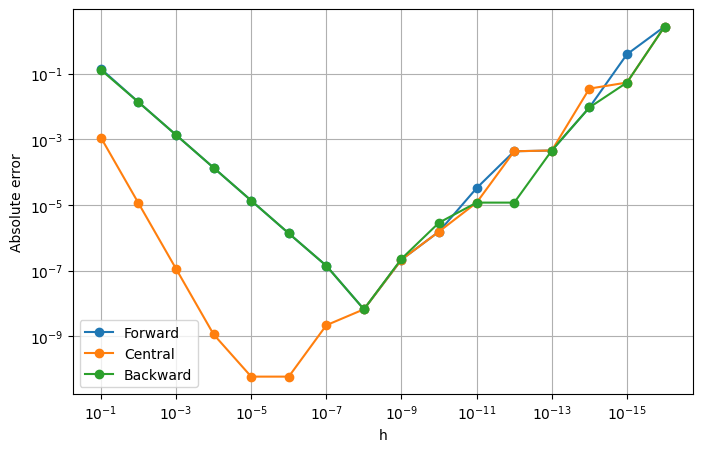

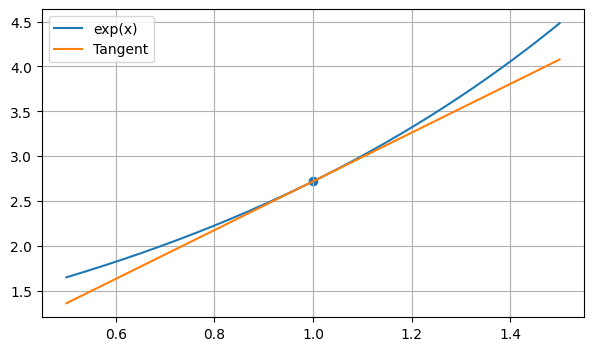

Exact derivative: 2.718281828459045
Best central h: 1e-06


In [5]:
x0 = 1.0
h_values = np.logspace(-1, -16, 16)
exact_derivative = np.exp(x0)
f_exp = np.exp
forward_values = (f_exp(x0 + h_values) - f_exp(x0)) / h_values
central_values = (f_exp(x0 + h_values / 2) - f_exp(x0 - h_values / 2)) / h_values
backward_values = (f_exp(x0) - f_exp(x0 - h_values)) / h_values
forward_errors = np.abs(forward_values - exact_derivative)
central_errors = np.abs(central_values - exact_derivative)
backward_errors = np.abs(backward_values - exact_derivative)

plt.figure(figsize=(8, 5))
plt.loglog(h_values, forward_errors, "o-", label="Forward")
plt.loglog(h_values, central_errors, "o-", label="Central")
plt.loglog(h_values, backward_errors, "o-", label="Backward")
plt.gca().invert_xaxis()
plt.xlabel("h")
plt.ylabel("Absolute error")
plt.legend()
plt.grid(True)
plt.show()

x_plot = np.linspace(0.5, 1.5, 300)
plt.figure(figsize=(7, 4))
plt.plot(x_plot, np.exp(x_plot), label="exp(x)")
plt.plot(x_plot, np.exp(x0) + exact_derivative * (x_plot - x0), label="Tangent")
plt.scatter([x0], [np.exp(x0)])
plt.legend()
plt.grid(True)
plt.show()
print("Exact derivative:", exact_derivative)
print("Best central h:", h_values[np.argmin(central_errors)])

### Задание 2.2. Правила дифференцирования

Источник условий: [практикум, с. 71, задачи 1, 2, 4 и 6](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=71).

Найдите производные и вычислите их при $x=1$:

$$
\begin{aligned}
&1)\quad y=2x^3-5x^2+7x+4;\\
&2)\quad y=x^2e^x;\\
&3)\quad y=(2x^2+5)^2;\\
&4)\quad y=\ln(2x^3+3x^2).
\end{aligned}
$$

- **[Бумага]** Для каждой функции назовите используемые правила и сохраните производную как функцию от $x$ до подстановки.
- **[Markdown]** Особо выделите внешний и внутренний аргументы в пунктах 3 и 4.
- **[Python]** Проверьте значения центральной разностью при $h=10^{-5}$.
- **[Интерпретация]** Сравните знаки и модули производных как локальные скорости изменения четырёх разных функций.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [6]:
x0 = 1.0
h = 1e-5

functions = [
    lambda x: 2*x**3 - 5*x**2 + 7*x + 4,
    lambda x: x**2 * np.exp(x),
    lambda x: (2*x**2 + 5)**2,
    lambda x: np.log(2*x**3 + 3*x**2),
]

derivatives = [
    lambda x: 6*x**2 - 10*x + 7,
    lambda x: np.exp(x) * (x**2 + 2*x),
    lambda x: 8*x*(2*x**2 + 5),
    lambda x: (6*x**2 + 6*x) / (2*x**3 + 3*x**2)
]
exact_values = np.array([df(x0) for df in derivatives])
numeric_values = np.array([
    (fn(x0 + h) - fn(x0 - h)) / (2*h) for fn in functions
])
print("Exact:", exact_values)
print("Central:", numeric_values)
print("Absolute errors:", np.abs(exact_values - numeric_values))

Exact: [ 3.        8.154845 56.        2.4     ]
Central: [ 3.        8.154845 56.        2.4     ]
Absolute errors: [0. 0. 0. 0.]


### Задание 2.3. Дифференциал и граница дифференцируемости

Источник первого условия: [практикум, с. 72, задача 2](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=72).

Для $y=\ln(1+x^2)$ найдите дифференциал $dy$ и используйте его для приближённого вычисления изменения при переходе от $x=1$ к $x=1.02$.

Затем исследуйте $r(x)=\max(0,x)$ в точке $x=0$.

- **[Бумага]** Найдите $dy=y'(x)dx$, левую и правую производные $r$ в нуле.
- **[Markdown]** Объясните, почему совпадение односторонних пределов необходимо для обычной производной.
- **[Python]** Сравните линейное приближение логарифмической функции с точным изменением; постройте $r(x)$ и её односторонние секущие. Вычислите центральную разность в нуле.
- **[Интерпретация]** Объясните, почему конечная центральная разность может вернуть число даже там, где производная не существует.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


Linear change: 0.02
Exact change: 0.019998686506689123
Left derivative: 0.0
Right derivative: 1.0
Central difference: 0.5


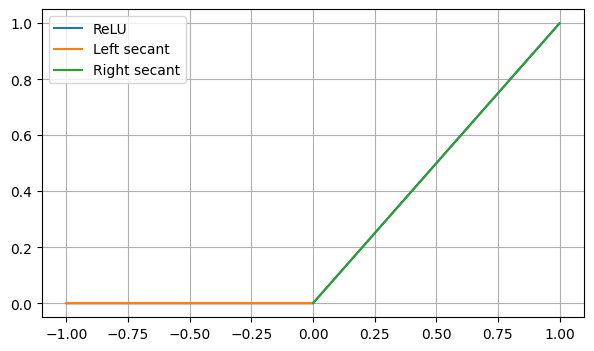

In [7]:
x0, dx = 1.0, 0.02
relu = lambda x: np.maximum(0.0, x)
h = 1e-5

linear_coefficient = 2*x0 / (1 + x0**2)
linear_change = linear_coefficient * dx
exact_change = np.log(1 + (x0 + dx)**2) - np.log(1 + x0**2)
print("Linear change:", linear_change)
print("Exact change:", exact_change)

left_derivative = (relu(0.0) - relu(-h)) / h
right_derivative = (relu(h) - relu(0.0)) / h
central_derivative = (relu(h) - relu(-h)) / (2*h)
print("Left derivative:", left_derivative)
print("Right derivative:", right_derivative)
print("Central difference:", central_derivative)

x_relu = np.linspace(-1, 1, 300)
plt.figure(figsize=(7, 4))
plt.plot(x_relu, relu(x_relu), label="ReLU")
plt.plot([-1, 0], [relu(-1), relu(0)], label="Left secant")
plt.plot([0, 1], [relu(0), relu(1)], label="Right secant")
plt.legend()
plt.grid(True)
plt.show()

## 3. Частные производные, градиент и дифференциал


### Короткая теория

Для $f:\mathbb R^n\to\mathbb R$ частная производная меняет только одну координату:

$$
\frac{\partial f}{\partial x_i}
=\lim_{h\to0}\frac{f(\mathbf x+h\mathbf e_i)-f(\mathbf x)}{h}.
$$

Все частные производные собираются в градиент

$$
\nabla f(\mathbf x)=
\begin{pmatrix}
\partial f/\partial x_1\\ \vdots\\ \partial f/\partial x_n
\end{pmatrix}.
$$

При малом $\Delta\mathbf x$ полный дифференциал задаёт линейное приближение

$$
\Delta f\approx df=\nabla f(\mathbf x)^{\mathsf T}\Delta\mathbf x.
$$

См. [градиент и частные производные, с. 40](../02-linear-algebra/linear-algebra.pdf#page=40).


### Задание 3.1. Полный дифференциал многочлена

Источник условия: [практикум, с. 140, задача 1в](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=140).

Для

$$
z=5x^3+2x^2y^4-6x+9y
$$

найдите $\partial z/\partial x$, $\partial z/\partial y$, градиент и полный дифференциал. Вычислите градиент в точке $(1,-1)$.

- **[Бумага]** При дифференцировании по одной переменной явно обозначьте другую как постоянную.
- **[Markdown]** Запишите $dz$ сначала через частные производные, затем в раскрытом виде.
- **[Python]** Проверьте обе компоненты градиента центральными покоординатными разностями.
- **[Интерпретация]** Объясните, почему коэффициент при $dx$ равен первой компоненте градиента, а коэффициент при $dy$ — второй.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [8]:
def z_practice(point):
    x, y = point
    return 5*x**3 + 2*x**2*y**4 - 6*x + 9*y

point = np.array([1.0, -1.0])
x, y = point
gradient_exact = np.array([15*x**2 + 4*x*y**4 - 6,
                           8*x**2*y**3 + 9], dtype=float)
gradient_numeric = np.array([
    (z_practice(point + np.eye(2)[i]*1e-5) -
     z_practice(point - np.eye(2)[i]*1e-5)) / (2e-5)
    for i in range(2)
])
print("Exact gradient:", gradient_exact)
print("Numeric gradient:", gradient_numeric)
print("Error norm:", np.linalg.norm(gradient_exact - gradient_numeric))

Exact gradient: [13.  1.]
Numeric gradient: [13.  1.]
Error norm: 8.683816026498536e-10


### Задание 3.2. Локальная плоскость вместо касательной

Пусть

$$
f(x,y)=x^2+xy+2y^2-3x+1,
\qquad \mathbf x_0=(1,-1)^{\mathsf T}.
$$

- **[Бумага]** Найдите $\nabla f$, $f(\mathbf x_0)$ и линейную модель $f(\mathbf x_0+\Delta\mathbf x)$.
- **[Markdown]** Для $\Delta\mathbf x=(0.01,-0.02)^{\mathsf T}$ вычислите прогноз изменения.
- **[Python]** Сравните прогноз с точным изменением. Постройте линии уровня, точку $\mathbf x_0$, градиент и выбранное приращение.
- **[Интерпретация]** Объясните геометрическое различие между касательной к графику одной переменной и касательной плоскостью для двух переменных.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


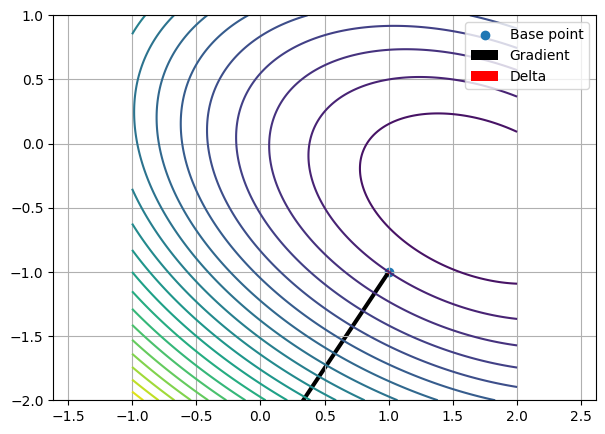

Base value: 0.0
Gradient: [-2. -3.]
Linear change: 0.04
Exact change: 0.040699999999999736


In [9]:
def f_quadratic(point):
    x, y = point
    return x**2 + x*y + 2*y**2 - 3*x + 1

x_base = np.array([1.0, -1.0])
delta = np.array([0.01, -0.02])

gradient_base = np.array([2*x_base[0] + x_base[1] - 3,
                           x_base[0] + 4*x_base[1]])
base_value = f_quadratic(x_base)
linear_change = gradient_base @ delta
exact_change = f_quadratic(x_base + delta) - base_value

grid_x, grid_y = np.meshgrid(np.linspace(-1, 2, 200), np.linspace(-2, 1, 200))
grid_z = grid_x**2 + grid_x*grid_y + 2*grid_y**2 - 3*grid_x + 1
plt.figure(figsize=(7, 5))
plt.contour(grid_x, grid_y, grid_z, levels=20)
plt.scatter(*x_base, label="Base point")
plt.quiver(*x_base, *gradient_base, angles="xy", scale_units="xy", scale=1, label="Gradient")
plt.quiver(*x_base, *delta, angles="xy", scale_units="xy", scale=1, color="red", label="Delta")
plt.legend()
plt.axis("equal")
plt.grid(True)
plt.show()
print("Base value:", base_value)
print("Gradient:", gradient_base)
print("Linear change:", linear_change)
print("Exact change:", exact_change)

### Задание 3.3. Численный градиент по координатам

- **[Бумага]** Запишите центральную разность для каждой компоненты $\nabla f(\mathbf x)$ через $\mathbf e_i$.
- **[Python]** Реализуйте функцию `central_gradient(f, x, h)`, не зашивая число координат. Проверьте её на функции из задания 3.2 для нескольких $h$.
- **[Markdown]** Сопоставьте аналитический и численный векторы и укажите норму ошибки.
- **[Интерпретация]** Посчитайте число обращений к $f$ для центральной разности в $n$ измерениях и объясните, почему цена растёт с размерностью.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [10]:
def central_gradient(function, point, h=1e-5):
    point = np.asarray(point, dtype=float)
    result = np.zeros_like(point)
    for i in range(point.size):
        step = np.zeros_like(point)
        step[i] = h
        result[i] = (function(point + step) - function(point - step)) / (2*h)
    return result

gradient_reference = np.array([2*x_base[0] + x_base[1] - 3,
                               x_base[0] + 4*x_base[1]])
for step_size in [1e-2, 1e-4, 1e-6, 1e-8]:
    estimate = central_gradient(f_quadratic, x_base, step_size)
    print("h:", step_size, "gradient:", estimate,
          "error norm:", np.linalg.norm(estimate - gradient_reference))

h: 0.01 gradient: [-2. -3.] error norm: 2.542192550933768e-14
h: 0.0001 gradient: [-2. -3.] error norm: 4.233536513861668e-12
h: 1e-06 gradient: [-2. -3.] error norm: 3.8736969842371417e-10
h: 1e-08 gradient: [-2. -3.] error norm: 2.0818590339445384e-08


## 4. Производная по направлению и полная производная


### Короткая теория

Производная по направлению $\mathbf v$ равна

$$
D_{\mathbf v}f(\mathbf x)
=\lim_{h\to0}\frac{f(\mathbf x+h\mathbf v)-f(\mathbf x)}{h}
=\nabla f(\mathbf x)^{\mathsf T}\mathbf v.
$$

При зависимых аргументах используется полная производная:

$$
\frac{dF}{dt}
=\frac{\partial F}{\partial t}
+\frac{\partial F}{\partial x}\frac{dx}{dt}
+\frac{\partial F}{\partial y}\frac{dy}{dt}.
$$

Оба оператора приведены в [теории, с. 40](../02-linear-algebra/linear-algebra.pdf#page=40).


### Задание 4.1. Изменение вдоль выбранного направления

Используйте функцию и точку из задания 3.2, а также единичный вектор

$$
\mathbf v=\frac15(3,4)^{\mathsf T}.
$$

- **[Бумага]** Вычислите $D_{\mathbf v}f(\mathbf x_0)$ и определите, возрастает или убывает функция при движении вдоль $\mathbf v$.
- **[Markdown]** Найдите единичные направления максимального роста и максимального убывания и соответствующие скорости.
- **[Python]** Проверьте направленную производную центральной разностью, меняя только один скаляр $h$.
- **[Интерпретация]** Объясните, почему направление необходимо нормировать, если требуется сравнивать именно скорость на единицу пути.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [11]:
x_base = np.array([1.0, -1.0])
v_direction = np.array([3.0, 4.0]) / 5.0

gradient_at_base = np.array([2*x_base[0] + x_base[1] - 3,
                               x_base[0] + 4*x_base[1]])
directional_derivative = gradient_at_base @ v_direction
unit_max_growth = gradient_at_base / np.linalg.norm(gradient_at_base)
unit_max_decrease = -unit_max_growth
directional_numeric = (f_quadratic(x_base + 1e-5*v_direction) -
                       f_quadratic(x_base - 1e-5*v_direction)) / (2e-5)
print("Directional derivative:", directional_derivative)
print("Maximum growth direction:", unit_max_growth)
print("Maximum decrease direction:", unit_max_decrease)
print("Maximum growth rate:", np.linalg.norm(gradient_at_base))
print("Maximum decrease rate:", -np.linalg.norm(gradient_at_base))
print("Numeric directional derivative:", directional_numeric)

Directional derivative: -3.6
Maximum growth direction: [-0.5547  -0.83205]
Maximum decrease direction: [0.5547  0.83205]
Maximum growth rate: 3.605551275463989
Maximum decrease rate: -3.605551275463989
Numeric directional derivative: -3.5999999999813954


### Задание 4.2. Все пути влияния переменной

Пусть

$$
F(t,x,y)=tx+x^2+xy+2y^2,
\qquad x(t)=t,
\qquad y(t)=t^2.
$$

- **[Бумага]** Найдите $dF/dt$ двумя способами: сначала подставьте $x(t),y(t)$, затем примените формулу полной производной.
- **[Markdown]** В формуле полной производной подпишите прямой путь $t\to F$ и косвенные пути $t\to x\to F$, $t\to y\to F$.
- **[Python]** Сравните оба выражения и центральную разность при $t=1$.
- **[Интерпретация]** Объясните, почему пропуск одного пути зависимости даёт неполную производную.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [12]:
def F_total(t, x, y):
    return t*x + x**2 + x*y + 2*y**2

def composed_F(t):
    return F_total(t, t, t**2)

def derivative_direct(t):
    return 8*t**3 + 3*t**2 + 4*t

def derivative_total(t):
    x, y = t, t**2
    partial_t = x
    partial_x = t + 2*x + y
    partial_y = x + 4*y
    return partial_t + partial_x*1 + partial_y*(2*t)

t0 = 1.0
h_fd = 1e-5
central_F = (composed_F(t0+h_fd) - composed_F(t0-h_fd)) / (2*h_fd)
print("Direct derivative:", derivative_direct(t0))
print("Total derivative:", derivative_total(t0))
print("Central difference:", central_F)

Direct derivative: 15.0
Total derivative: 15.0
Central difference: 15.000000000942036


## 5. Якобиан, JVP, VJP и цепное правило


### Короткая теория

Для $\mathbf f:\mathbb R^n\to\mathbb R^m$ якобиан имеет размер $m\times n$:

$$
\mathbf J_{\mathbf f}(\mathbf x)=
\begin{pmatrix}
\nabla f_1(\mathbf x)^{\mathsf T}\\
\vdots\\
\nabla f_m(\mathbf x)^{\mathsf T}
\end{pmatrix}.
$$

Произведение $\mathbf J\mathbf v$ называется JVP, а $\mathbf u^{\mathsf T}\mathbf J$ — VJP. Для композиции $\mathbf h=\mathbf g\circ\mathbf f$

$$
\mathbf J_{\mathbf h}(\mathbf x)
=\mathbf J_{\mathbf g}(\mathbf f(\mathbf x))\mathbf J_{\mathbf f}(\mathbf x).
$$

См. [якобиан, JVP, VJP и цепное правило, с. 41](../02-linear-algebra/linear-algebra.pdf#page=41).


### Задание 5.1. Якобиан векторной функции

Рассмотрите

$$
\mathbf f(x_1,x_2)=
\begin{pmatrix}
x_1^2+x_2\\
e^{x_1-x_2}\\
x_1x_2
\end{pmatrix}.
$$

- **[Бумага]** Найдите все шесть частных производных и соберите якобиан.
- **[Markdown]** Укажите размерности входа, выхода и якобиана. Вычислите $\mathbf f$ и $\mathbf J_{\mathbf f}$ в точке $\mathbf x_*=(1,0)^{\mathsf T}$.
- **[Python]** Реализуйте `vector_function` и `jacobian_exact`, проверьте строки якобиана покоординатными разностями.
- **[Интерпретация]** Объясните, что означает элемент $J_{ij}$ и почему градиенты компонент выхода расположены по строкам.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [13]:
def vector_function(point):
    x1, x2 = point
    return np.array([x1**2 + x2, np.exp(x1 - x2), x1*x2])

x_star = np.array([1.0, 0.0])

def jacobian_exact(point):
    x1, x2 = point
    return np.array([[2*x1, 1],
                     [np.exp(x1-x2), -np.exp(x1-x2)],
                     [x2, x1]], dtype=float)

J_exact = jacobian_exact(x_star)
J_numeric = np.vstack([central_gradient(lambda p, i=i: vector_function(p)[i],
                                        x_star, 1e-5) for i in range(3)])
print("Function value:", vector_function(x_star))
print("Exact Jacobian:", J_exact)
print("Numeric Jacobian:", J_numeric)
print("Error norm:", np.linalg.norm(J_exact - J_numeric))

Function value: [1.       2.718282 0.      ]
Exact Jacobian: [[ 2.        1.      ]
 [ 2.718282 -2.718282]
 [ 0.        1.      ]]
Numeric Jacobian: [[ 2.        1.      ]
 [ 2.718282 -2.718282]
 [ 0.        1.      ]]
Error norm: 8.288458036275357e-11


### Задание 5.2. JVP без полного численного якобиана

Пусть $\mathbf v=(1,-2)^{\mathsf T}$.

- **[Бумага]** Вычислите $\mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v$.
- **[Markdown]** Запишите центральную аппроксимацию

  $$
  \mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v
  \approx
  \frac{\mathbf f(\mathbf x_*+h\mathbf v/2)-
  \mathbf f(\mathbf x_*-h\mathbf v/2)}{h}.
  $$

- **[Python]** Сравните точное и численное JVP для разных $h$, постройте график нормы ошибки.
- **[Интерпретация]** Объясните, почему для численного JVP нужны два обращения к $\mathbf f$ независимо от числа входных координат.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


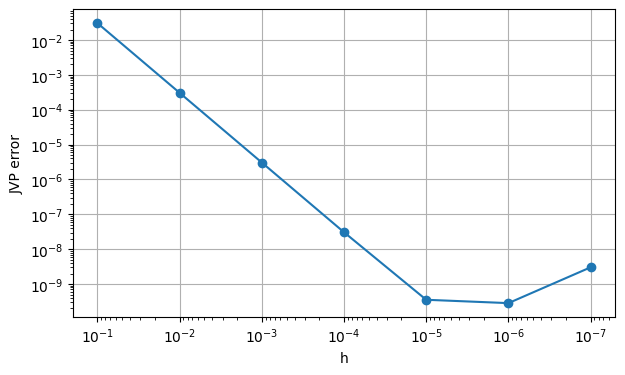

Exact JVP: [ 0.        8.154845 -2.      ]
JVP errors: [np.float64(0.03061509226063741), np.float64(0.00030581014604180723), np.float64(3.0580670351554318e-06), np.float64(3.058699079860279e-08), np.float64(3.5339731141448283e-10), np.float64(2.831889056248153e-10), np.float64(3.018462363900565e-09)]


In [14]:
v_jvp = np.array([1.0, -2.0])

J_at_star = jacobian_exact(x_star)
exact_jvp = J_at_star @ v_jvp
h_values_jvp = np.logspace(-1, -7, 7)
jvp_errors = []
for step_size in h_values_jvp:
    estimate = (vector_function(x_star + step_size*v_jvp/2) -
                vector_function(x_star - step_size*v_jvp/2)) / step_size
    jvp_errors.append(np.linalg.norm(estimate - exact_jvp))
plt.figure(figsize=(7, 4))
plt.loglog(h_values_jvp, jvp_errors, "o-")
plt.gca().invert_xaxis()
plt.xlabel("h")
plt.ylabel("JVP error")
plt.grid(True)
plt.show()
print("Exact JVP:", exact_jvp)
print("JVP errors:", jvp_errors)

### Задание 5.3. VJP и производная композиции

Сначала для $\mathbf u=(1,2,-1)^{\mathsf T}$ вычислите $\mathbf u^{\mathsf T}\mathbf J_{\mathbf f}(\mathbf x_*)$. Затем определите

$$
g(\mathbf z)=\frac12\lVert\mathbf z-\mathbf c\rVert_2^2,
\qquad
\mathbf c=(0,1,1)^{\mathsf T},
\qquad
h(\mathbf x)=g(\mathbf f(\mathbf x)).
$$

- **[Бумага]** Найдите $\nabla_{\mathbf z}g$ и $\nabla_{\mathbf x}h=\mathbf J_{\mathbf f}^{\mathsf T}\nabla_{\mathbf z}g$ в точке $\mathbf x_*$.
- **[Markdown]** Проверьте размерности каждого множителя и результата цепного правила.
- **[Python]** Сравните аналитический градиент композиции с `central_gradient`.
- **[Интерпретация]** Объясните, как VJP передаёт чувствительность одного скалярного результата ко всем входным координатам.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [15]:
u_vjp = np.array([1.0, 2.0, -1.0])
c_target = np.array([0.0, 1.0, 1.0])

vjp_value = u_vjp @ jacobian_exact(x_star)

def composed_loss(point):
    difference = vector_function(point) - c_target
    return 0.5 * difference @ difference

gradient_z = vector_function(x_star) - c_target
gradient_h_exact = jacobian_exact(x_star).T @ gradient_z
gradient_h_numeric = central_gradient(composed_loss, x_star)
print("VJP:", vjp_value)
print("Gradient of composition:", gradient_h_exact)
print("Numeric gradient:", gradient_h_numeric)
print("Error norm:", np.linalg.norm(gradient_h_exact-gradient_h_numeric))

VJP: [ 7.436564 -5.436564]
Gradient of composition: [ 6.670774 -4.670774]
Numeric gradient: [ 6.670774 -4.670774]
Error norm: 8.15363047149833e-10


## 6. Гессиан и кривизна


### Короткая теория

Гессиан дважды дифференцируемой функции $f:\mathbb R^n\to\mathbb R$ — якобиан градиента:

$$
\mathbf H_f(\mathbf x)=\nabla^2f(\mathbf x)
=\begin{pmatrix}
\frac{\partial^2f}{\partial x_1^2}&\cdots&\frac{\partial^2f}{\partial x_1\partial x_n}\\
\vdots&\ddots&\vdots\\
\frac{\partial^2f}{\partial x_n\partial x_1}&\cdots&\frac{\partial^2f}{\partial x_n^2}
\end{pmatrix}.
$$

В стационарной точке положительно определённый гессиан указывает на локальный минимум, отрицательно определённый — на максимум, а неопределённый — на седловую точку. См. [гессиан, с. 41–42](../02-linear-algebra/linear-algebra.pdf#page=41), [положительно определённые матрицы, с. 13](../02-linear-algebra/linear-algebra.pdf#page=13) и [геометрию квадратичных форм, с. 27](../02-linear-algebra/linear-algebra.pdf#page=27).

![Геометрия квадратичной формы](../02-linear-algebra/assets/figures/figure-06.png)

*Собственные направления симметричной матрицы задают главные направления кривизны квадратичной формы.*


### Задание 6.1. Положительная кривизна и минимум

Источник условия: [практикум, с. 142, задача 1](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=142).

Исследуйте на экстремум

$$
z=2x^2+y^2+x-3y+2xy.
$$

- **[Бумага]** Найдите стационарную точку, гессиан, его определитель и собственные значения.
- **[Markdown]** Классифицируйте точку и вычислите значение функции.
- **[Python]** Проверьте решение, постройте линии уровня и отметьте стационарную точку.
- **[Интерпретация]** Свяжите положительные собственные значения с ростом функции во всех достаточно малых направлениях от минимума.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


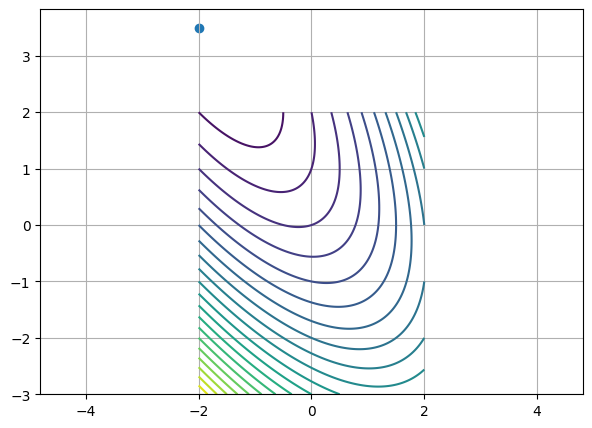

Stationary point: [-2.   3.5]
Hessian: [[4. 2.]
 [2. 2.]]
Determinant: 4.0
Eigenvalues: [0.763932 5.236068]
Function value: -6.25


In [16]:
def minimum_function(point):
    x, y = point
    return 2*x**2 + y**2 + x - 3*y + 2*x*y

stationary_minimum = np.linalg.solve(np.array([[4., 2.], [2., 2.]]),
                                      np.array([-1., 3.]))
hessian_minimum = np.array([[4., 2.], [2., 2.]])
eigenvalues_minimum, eigenvectors_minimum = np.linalg.eigh(hessian_minimum)
minimum_value = minimum_function(stationary_minimum)
grid_x, grid_y = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-3, 2, 200))
grid_z = 2*grid_x**2 + grid_y**2 + grid_x - 3*grid_y + 2*grid_x*grid_y
plt.figure(figsize=(7, 5))
plt.contour(grid_x, grid_y, grid_z, levels=25)
plt.scatter(*stationary_minimum)
plt.grid(True)
plt.axis("equal")
plt.show()
print("Stationary point:", stationary_minimum)
print("Hessian:", hessian_minimum)
print("Determinant:", np.linalg.det(hessian_minimum))
print("Eigenvalues:", eigenvalues_minimum)
print("Function value:", minimum_value)

### Задание 6.2. Неопределённая кривизна и седло

Источник условия: [практикум, с. 142, задача 3](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=142).

Исследуйте

$$
z=x^2-2y^2-4xy+3x.
$$

- **[Бумага]** Найдите стационарную точку, гессиан, определитель и собственные значения.
- **[Markdown]** Покажите два направления, вдоль которых квадратичное изменение имеет разные знаки.
- **[Python]** Постройте линии уровня и трёхмерную поверхность около стационарной точки.
- **[Интерпретация]** Объясните, почему нулевой градиент ещё не гарантирует минимум.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


Stationary point: [-0.5  0.5]
Hessian: [[ 2. -4.]
 [-4. -4.]]
Determinant: -23.999999999999993
Eigenvalues: [-6.  4.]
Function value: -0.75
Positive direction: [-0.894427  0.447214]
Negative direction: [0.447214 0.894427]


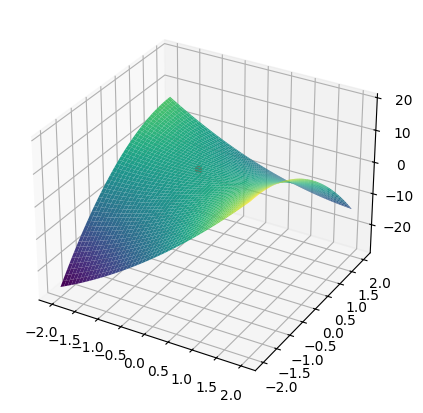

In [17]:
def saddle_function(point):
    x, y = point
    return x**2 - 2*y**2 - 4*x*y + 3*x

stationary_saddle = np.linalg.solve(np.array([[2., -4.], [-4., -4.]]),
                                    np.array([-3., 0.]))
hessian_saddle = np.array([[2., -4.], [-4., -4.]])
eigenvalues_saddle, eigenvectors_saddle = np.linalg.eigh(hessian_saddle)
saddle_value = saddle_function(stationary_saddle)
direction_positive = eigenvectors_saddle[:, np.argmax(eigenvalues_saddle)]
direction_negative = eigenvectors_saddle[:, np.argmin(eigenvalues_saddle)]
print("Stationary point:", stationary_saddle)
print("Hessian:", hessian_saddle)
print("Determinant:", np.linalg.det(hessian_saddle))
print("Eigenvalues:", eigenvalues_saddle)
print("Function value:", saddle_value)
print("Positive direction:", direction_positive)
print("Negative direction:", direction_negative)

grid_x, grid_y = np.meshgrid(np.linspace(-2, 2, 100), np.linspace(-2, 2, 100))
grid_z = grid_x**2 - 2*grid_y**2 - 4*grid_x*grid_y + 3*grid_x
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(grid_x, grid_y, grid_z, cmap="viridis", linewidth=0)
ax.scatter(*stationary_saddle, saddle_value, color="red")
plt.show()

### Задание 6.3. Квадратичная модель и HVP

Пусть

$$
\varphi(x,y)=e^{x+2y}+x^2,
\qquad \mathbf x_0=(0,0)^{\mathsf T}.
$$

- **[Бумага]** Найдите $\nabla\varphi(\mathbf x_0)$, $\mathbf H_\varphi(\mathbf x_0)$ и второе приближение

  $$
  \varphi(\mathbf x_0+\Delta)
  \approx \varphi(\mathbf x_0)
  +\nabla\varphi(\mathbf x_0)^{\mathsf T}\Delta
  +\frac12\Delta^{\mathsf T}\mathbf H_\varphi(\mathbf x_0)\Delta
  $$

  для $\Delta=(0.1,0.1)^{\mathsf T}$.
- **[Markdown]** Для $\mathbf v=(1,-1)^{\mathsf T}$ вычислите $\mathbf H\mathbf v$.
- **[Python]** Проверьте HVP центральной разностью градиента и сравните точное значение функции с линейным и квадратичным приближениями при уменьшающемся масштабе $\Delta$.
- **[Интерпретация]** Объясните, какую дополнительную информацию даёт квадратичный член по сравнению с одним градиентом.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [18]:
def phi(point):
    x, y = point
    return np.exp(x + 2*y) + x**2

def phi_gradient(point):
    x, y = point
    exponential = np.exp(x + 2*y)
    return np.array([exponential + 2*x, 2*exponential])

def phi_hessian(point):
    x, y = point
    exponential = np.exp(x + 2*y)
    return np.array([[exponential + 2, 2*exponential],
                     [2*exponential, 4*exponential]])

x_phi = np.array([0.0, 0.0])
delta_phi = np.array([0.1, 0.1])
gradient_phi = phi_gradient(x_phi)
hessian_phi = phi_hessian(x_phi)
linear_approx = phi(x_phi) + gradient_phi @ delta_phi
quadratic_approx = linear_approx + 0.5 * delta_phi @ hessian_phi @ delta_phi
v_hvp = np.array([1.0, -1.0])
exact_hvp = hessian_phi @ v_hvp
print("Gradient:", gradient_phi)
print("Hessian:", hessian_phi)
print("Linear approximation:", linear_approx)
print("Quadratic approximation:", quadratic_approx)
print("Exact HVP:", exact_hvp)

scales = np.array([1.0, 0.5, 0.25, 0.1, 0.05])
for scale in scales:
    displacement = scale * delta_phi
    approx_linear = phi(x_phi) + gradient_phi @ displacement
    approx_quadratic = approx_linear + 0.5*displacement @ hessian_phi @ displacement
    print("Scale:", scale, "Exact:", phi(x_phi+displacement),
          "Linear:", approx_linear, "Quadratic:", approx_quadratic)
h_hvp = 1e-5
numeric_hvp = (phi_gradient(x_phi+h_hvp*v_hvp) -
               phi_gradient(x_phi-h_hvp*v_hvp)) / (2*h_hvp)
print("Numeric HVP:", numeric_hvp)

Gradient: [1. 2.]
Hessian: [[3. 2.]
 [2. 4.]]
Linear approximation: 1.3
Quadratic approximation: 1.355
Exact HVP: [ 1. -2.]
Scale: 1.0 Exact: 1.3598588075760032 Linear: 1.3 Quadratic: 1.355
Scale: 0.5 Exact: 1.164334242728283 Linear: 1.15 Quadratic: 1.1637499999999998
Scale: 0.25 Exact: 1.0785091508846316 Linear: 1.075 Quadratic: 1.0784375
Scale: 0.1 Exact: 1.030554533953517 Linear: 1.03 Quadratic: 1.03055
Scale: 0.05 Exact: 1.0151380646157189 Linear: 1.015 Quadratic: 1.0151374999999998
Numeric HVP: [ 1. -2.]


## 7. Матричное дифференцирование


### Короткая теория

Для векторного аргумента полезны тождества

$$
\frac{\partial(\mathbf a^{\mathsf T}\mathbf x)}{\partial\mathbf x}=\mathbf a,
\qquad
\frac{\partial(\mathbf x^{\mathsf T}\mathbf A\mathbf x)}{\partial\mathbf x}
=(\mathbf A+\mathbf A^{\mathsf T})\mathbf x.
$$

Для матричного аргумента производная скалярной функции имеет ту же форму, что и матрица:

$$
\left(\frac{\partial f}{\partial\mathbf X}\right)_{ij}
=\frac{\partial f}{\partial X_{ij}}.
$$

В частности,

$$
\frac{\partial}{\partial\mathbf X}
(\mathbf a^{\mathsf T}\mathbf X\mathbf b)
=\mathbf a\mathbf b^{\mathsf T},
\qquad
\frac{\partial}{\partial\mathbf X}
\operatorname{tr}(\mathbf X^{\mathsf T}\mathbf A)=\mathbf A.
$$

См. [векторные градиенты, с. 42](../02-linear-algebra/linear-algebra.pdf#page=42) и [матричные и следовые тождества, с. 42–43](../02-linear-algebra/linear-algebra.pdf#page=42).


### Задание 7.1. Линейно-квадратичная форма

Для

$$
f(\mathbf x)=\mathbf a^{\mathsf T}\mathbf x+mathbf x^{\mathsf T}\mathbf A\mathbf x,
$$

$$
\mathbf A=\begin{pmatrix}2&-1\\3&1\end{pmatrix},
\quad
\mathbf a=\begin{pmatrix}1\\-2\end{pmatrix},
\quad
\mathbf x=\begin{pmatrix}2\\-1\end{pmatrix},
$$

найдите значение, градиент и гессиан.

- **[Бумага]** Сначала раскройте выражение покоординатно, затем примените матричное тождество.
- **[Markdown]** Объясните появление симметричной части $\mathbf A+\mathbf A^{\mathsf T}$.
- **[Python]** Проверьте градиент и гессиан конечными разностями.
- **[Интерпретация]** Покажите, что кососимметричная часть $\mathbf A$ не влияет на $\mathbf x^{\mathsf T}\mathbf A\mathbf x$.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [19]:
A_quad = np.array([[2, -1], [3, 1]], dtype=float)
a_quad = np.array([1.0, -2.0])
x_quad = np.array([2.0, -1.0])

def quadratic_form(point):
    return a_quad @ point + point @ A_quad @ point

quadratic_value = quadratic_form(x_quad)
quadratic_gradient = a_quad + (A_quad + A_quad.T) @ x_quad
quadratic_hessian = A_quad + A_quad.T
symmetric_part = 0.5 * (A_quad + A_quad.T)
skew_part = 0.5 * (A_quad - A_quad.T)
skew_contribution = x_quad @ skew_part @ x_quad
gradient_numeric_quad = central_gradient(quadratic_form, x_quad)
hessian_numeric_quad = np.column_stack([
    ( (a_quad + (A_quad + A_quad.T) @ (x_quad + np.eye(2)[i]*1e-5)) -
      (a_quad + (A_quad + A_quad.T) @ (x_quad - np.eye(2)[i]*1e-5)) ) / (2e-5)
    for i in range(2)
])
print("Function value:", quadratic_value)
print("Gradient:", quadratic_gradient)
print("Hessian:", quadratic_hessian)
print("Skew contribution:", skew_contribution)
print("Numeric gradient:", gradient_numeric_quad)
print("Numeric Hessian:", hessian_numeric_quad)

Function value: 9.0
Gradient: [7. 0.]
Hessian: [[4. 2.]
 [2. 2.]]
Skew contribution: 0.0
Numeric gradient: [ 7. -0.]
Numeric Hessian: [[4. 2.]
 [2. 2.]]


### Задание 7.2. Производная по матрице

Пусть

$$
s(\mathbf M)=\mathbf a^{\mathsf T}\mathbf M\mathbf b,
\quad
\mathbf a=(1,-2)^{\mathsf T},
\quad
\mathbf b=(3,1,-1)^{\mathsf T},
$$

$$
\mathbf M=
\begin{pmatrix}1&2&0\\-1&3&4\end{pmatrix}.
$$

- **[Бумага]** Раскройте $s=\sum_i\sum_j a_iM_{ij}b_j$ и найдите каждую $\partial s/\partial M_{ij}$.
- **[Markdown]** Сверните результат в $\mathbf a\mathbf b^{\mathsf T}$ и перепишите скаляр через след.
- **[Python]** Изменяйте каждый элемент $M_{ij}$ отдельно и сравните численный градиент с внешним произведением.
- **[Интерпретация]** Объясните, почему форма градиента совпадает с формой матрицы параметров.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [20]:
a_matrix = np.array([1.0, -2.0])
b_matrix = np.array([3.0, 1.0, -1.0])
M_parameter = np.array([[1, 2, 0], [-1, 3, 4]], dtype=float)

matrix_value = a_matrix @ M_parameter @ b_matrix
matrix_gradient_exact = np.outer(a_matrix, b_matrix)
matrix_gradient_numeric = np.zeros_like(M_parameter)
h_matrix = 1e-6
for i in range(M_parameter.shape[0]):
    for j in range(M_parameter.shape[1]):
        perturbation = np.zeros_like(M_parameter)
        perturbation[i, j] = h_matrix
        plus = a_matrix @ (M_parameter + perturbation) @ b_matrix
        minus = a_matrix @ (M_parameter - perturbation) @ b_matrix
        matrix_gradient_numeric[i, j] = (plus - minus) / (2*h_matrix)
print("Function value:", matrix_value)
print("Exact matrix gradient:", matrix_gradient_exact)
print("Numeric matrix gradient:", matrix_gradient_numeric)

Function value: 13.0
Exact matrix gradient: [[ 3.  1. -1.]
 [-6. -2.  2.]]
Numeric matrix gradient: [[ 3.  1. -1.]
 [-6. -2.  2.]]


### Задание 7.3. Сумма потерь, след и матричный градиент

Для общего пакета данных определим

$$
Q(\mathbf W)=\frac{1}{2N}\lVert\mathbf X\mathbf W-\mathbf Y\rVert_F^2.
$$

- **[Бумага]** Запишите $Q$ тремя способами:

  $$
  Q=\frac{1}{2N}\sum_{n=1}^N\sum_{k=1}^K
  \left(\sum_{d=1}^D X_{nd}W_{dk}-Y_{nk}\right)^2,
  $$

  через норму Фробениуса и через след.
- **[Markdown]** Выведите по индексам

  $$
  \nabla_{\mathbf W}Q
  =\frac1N\mathbf X^{\mathsf T}(\mathbf X\mathbf W-\mathbf Y)
  $$

  и действие гессиана на матрицу-направление $\Delta\mathbf W$.
- **[Python]** Вычислите $Q(\mathbf W_0)$, градиент и проверьте каждый элемент конечными разностями.
- **[Интерпретация]** Сопоставьте индексы $d,k$ у градиента индексам параметра $W_{dk}$.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [21]:
def matrix_least_squares(W):
    residual = X_data @ W - Y_data
    return 0.5 * np.sum(residual**2) / len(X_data)

def matrix_least_squares_gradient(W):
    return X_data.T @ (X_data @ W - Y_data) / len(X_data)

def matrix_least_squares_hvp(direction):
    return X_data.T @ (X_data @ direction) / len(X_data)

gradient_ls = matrix_least_squares_gradient(W_initial)
numeric_gradient_ls = np.zeros_like(W_initial)
h_ls = 1e-6
for i in range(W_initial.shape[0]):
    for j in range(W_initial.shape[1]):
        perturbation = np.zeros_like(W_initial)
        perturbation[i, j] = h_ls
        numeric_gradient_ls[i, j] = (
            matrix_least_squares(W_initial + perturbation) -
            matrix_least_squares(W_initial - perturbation)
        ) / (2*h_ls)
print("Loss:", matrix_least_squares(W_initial))
print("Analytic gradient:", gradient_ls)
print("Numeric gradient:", numeric_gradient_ls)
print("HVP:", matrix_least_squares_hvp(np.ones_like(W_initial)))

Loss: 0.3775
Analytic gradient: [[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]
Numeric gradient: [[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]
HVP: [[0. 0.]
 [2. 2.]
 [1. 1.]]


## 8. Сквозная составная функция


### Короткая теория

Для сигмоиды

$$
\sigma(z)=\frac{1}{1+e^{-z}},
\qquad
\sigma'(z)=\sigma(z)(1-\sigma(z)).
$$

В матричном выражении нелинейная функция применяется поэлементно. Чтобы не смешивать матричное и поэлементное умножение, будем обозначать последнее символом $\odot$.

Цепное правило для композиции применяется от скалярного результата к каждому промежуточному аргументу. Это та же идея, что произведение якобианов и VJP на [с. 41](../02-linear-algebra/linear-algebra.pdf#page=41), но записанная сразу в формах нужных массивов.


### Задание 8.1. Прямое вычисление и размерности

- **[Бумага]** Для элемента $Z_{nk}$ запишите

  $$
  Z_{nk}=\sum_{d=1}^{D}X_{nd}W_{dk}+b_k.
  $$

  Затем запишите $H_{nk}$ и $\mathcal L$ как суммы по индексам.
- **[Markdown]** Составьте таблицу объектов $\mathbf X,\mathbf W,\mathbf b,\mathbf Z,\mathbf H,\mathbf Y,\mathcal L$ с размерностями и типами.
- **[Python]** Выполните прямое вычисление с начальными параметрами. Для устойчивости ограничьте аргумент `exp` диапазоном `[-50, 50]`.
- **[Интерпретация]** Объясните, почему добавление $\mathbf b$ к каждой строке является расширением по строкам, а не матричным произведением двух исходных массивов.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [22]:
Z = X_data @ W_initial + b_initial
H = sigmoid(Z)
residual = H - Y_data
loss_data = 0.5 * np.sum(residual**2) / len(X_data)
loss_regularization = 0.5 * regularization * np.sum(W_initial**2)
loss_total = loss_data + loss_regularization
print("Shapes:", X_data.shape, W_initial.shape, b_initial.shape,
      Z.shape, H.shape, Y_data.shape)
print("Loss components:", loss_data, loss_regularization, loss_total)
print("Manual Z[0,0]:", np.dot(X_data[0], W_initial[:, 0]) + b_initial[0])
print("Computed Z[0,0]:", Z[0, 0])

Shapes: (4, 3) (3, 2) (2,) (4, 2) (4, 2) (4, 2)
Loss components: 0.12048910430482579 0.014750000000000003 0.1352391043048258
Manual Z[0,0]: 0.7999999999999999
Computed Z[0,0]: 0.7999999999999999


### Задание 8.2. Распространение производных по композиции

Обозначьте $\mathbf R=\mathbf H-\mathbf Y$.

- **[Бумага]** Последовательно получите

  $$
  \mathbf G_H=\frac{1}{N}\mathbf R,
  \qquad
  \mathbf G_Z=\mathbf G_H\odot\mathbf H\odot(1-\mathbf H),
  $$

  $$
  \nabla_{\mathbf W}\mathcal L
  =\mathbf X^{\mathsf T}\mathbf G_Z+\lambda\mathbf W,
  \qquad
  \nabla_{\mathbf b}\mathcal L
  =\mathbf G_Z^{\mathsf T}\mathbf1_N.
  $$
- **[Markdown]** После каждой строки подпишите размерность. Отдельно объясните происхождение $\lambda\mathbf W$.
- **[Python]** Реализуйте одну функцию, возвращающую $\mathcal L$, $\nabla_{\mathbf W}\mathcal L$ и $\nabla_{\mathbf b}\mathcal L$.
- **[Интерпретация]** Опишите вычисление производных как движение по композиции в порядке, обратном прямому вычислению значений.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [23]:
def objective_and_grad(W, b):
    Z_local = X_data @ W + b
    H_local = sigmoid(Z_local)
    R_local = H_local - Y_data
    N = X_data.shape[0]
    data_loss = 0.5 * np.sum(R_local**2) / N
    reg_loss = 0.5 * regularization * np.sum(W**2)
    loss = data_loss + reg_loss
    G_H = R_local / N
    G_Z = G_H * H_local * (1 - H_local)
    grad_W = X_data.T @ G_Z + regularization * W
    grad_b = np.sum(G_Z, axis=0)
    return loss, grad_W, grad_b

loss_initial, grad_W_initial, grad_b_initial = objective_and_grad(W_initial, b_initial)
print("Initial loss:", loss_initial)
print("Gradient shapes:", grad_W_initial.shape, grad_b_initial.shape)
print("Gradient norm:", np.sqrt(np.sum(grad_W_initial**2) + np.sum(grad_b_initial**2)))

Initial loss: 0.1352391043048258
Gradient shapes: (3, 2) (2,)
Gradient norm: 0.10463950563500041


### Задание 8.3. Проверка каждого параметра

- **[Бумага]** Запишите центральную разность для одного элемента $W_{dk}$ и одного элемента $b_k$.
- **[Python]** Реализуйте универсальную численную проверку, поочерёдно возмущающую каждый элемент $\mathbf W$ и $\mathbf b$ при $h=10^{-6}$.
- **[Markdown]** Выведите аналитические и численные градиенты, максимальную абсолютную и относительную ошибки.
- **[Интерпретация]** Если проверка не проходит, перечислите порядок диагностики: коэффициент $1/N$, знак остатка, производная сигмоиды, транспонирование, сумма по строкам и регуляризация.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


In [24]:
def numerical_parameter_gradients(W, b, h=1e-6):
    numeric_W = np.zeros_like(W, dtype=float)
    numeric_b = np.zeros_like(b, dtype=float)
    for i in range(W.shape[0]):
        for j in range(W.shape[1]):
            W_plus, W_minus = W.copy(), W.copy()
            W_plus[i, j] += h
            W_minus[i, j] -= h
            numeric_W[i, j] = (objective_and_grad(W_plus, b)[0] -
                               objective_and_grad(W_minus, b)[0]) / (2*h)
    for j in range(b.size):
        b_plus, b_minus = b.copy(), b.copy()
        b_plus[j] += h
        b_minus[j] -= h
        numeric_b[j] = (objective_and_grad(W, b_plus)[0] -
                        objective_and_grad(W, b_minus)[0]) / (2*h)
    return numeric_W, numeric_b

numeric_W, numeric_b = numerical_parameter_gradients(W_initial, b_initial)
abs_error_W = np.abs(grad_W_initial - numeric_W)
abs_error_b = np.abs(grad_b_initial - numeric_b)
relative_error_W = abs_error_W / np.maximum(1e-12, np.abs(grad_W_initial) + np.abs(numeric_W))
relative_error_b = abs_error_b / np.maximum(1e-12, np.abs(grad_b_initial) + np.abs(numeric_b))
print("Analytic W gradient:", grad_W_initial)
print("Numeric W gradient:", numeric_W)
print("Analytic b gradient:", grad_b_initial)
print("Numeric b gradient:", numeric_b)
print("Maximum absolute error:", max(abs_error_W.max(), abs_error_b.max()))
print("Maximum relative error:", max(relative_error_W.max(), relative_error_b.max()))

Analytic W gradient: [[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
Numeric W gradient: [[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
Analytic b gradient: [ 0.045317 -0.015683]
Numeric b gradient: [ 0.045317 -0.015683]
Maximum absolute error: 7.289273351585024e-12
Maximum relative error: 3.1597556217764285e-09


## 9. Численная оптимизация


### Короткая теория

После проверки градиента параметры можно обновлять в направлении убывания:

$$
\mathbf W^{(r+1)}=\mathbf W^{(r)}-\eta\nabla_{\mathbf W}\mathcal L,
\qquad
\mathbf b^{(r+1)}=\mathbf b^{(r)}-\eta\nabla_{\mathbf b}\mathcal L,
$$

где $\eta>0$ — шаг. Производная локальна: слишком большой шаг может вывести параметры за область, где линейное приближение правильно предсказывает изменение функции.


### Задание 9.1. Шаг, траектория и устойчивость

- **[Бумага]** Используя начальный градиент, предскажите знак первого изменения $\mathcal L$ для достаточно малого $\eta$.
- **[Python]** Выполните 100 обновлений из одинаковой начальной точки для $\eta\in\{0.1,1,20\}$. Сохраните историю функции и нормы градиента. Постройте графики в логарифмическом масштабе.
- **[Markdown]** Для каждого шага укажите начальное и конечное значения, минимальное значение, номер лучшей итерации и наличие увеличений.
- **[Интерпретация]** Объясните различие между медленным устойчивым уменьшением, быстрым устойчивым уменьшением и нестабильной траекторией. Не делайте вывода только по последней точке — используйте всю историю.


#### Ваше решение

**Аналитическая часть.**  
_Запишите определения, промежуточные действия, проверку размерностей и точный результат._

**Численная проверка и интерпретация.**  
_После выполнения кода сопоставьте числа или график с аналитическим выводом и объясните смысл результата._


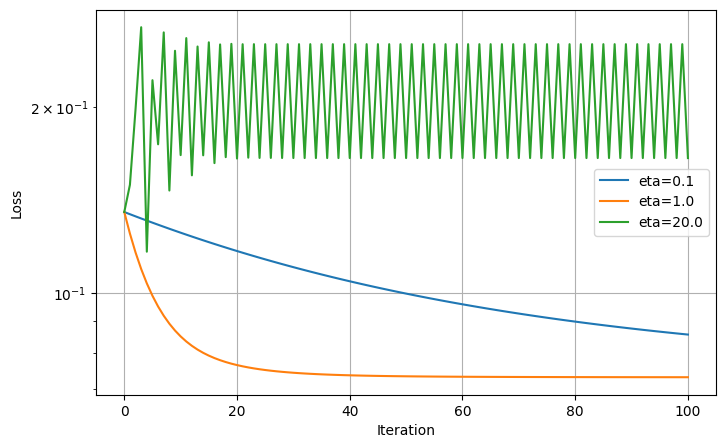

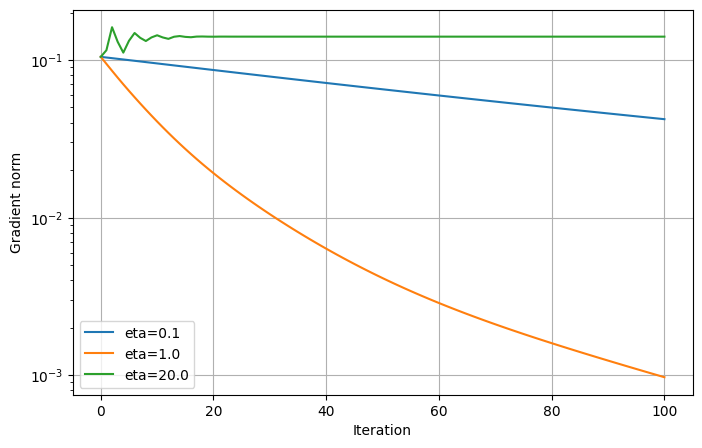

Learning rate: 0.1 Initial: 0.1352391043048258 Final: 0.08571754199494216 Minimum: 0.08571754199494216 Best iteration: 100 Increases: 0
Learning rate: 1.0 Initial: 0.1352391043048258 Final: 0.07313292195346406 Minimum: 0.07313292195346406 Best iteration: 100 Increases: 0
Learning rate: 20.0 Initial: 0.1352391043048258 Final: 0.16532150866545622 Minimum: 0.11668190414354414 Best iteration: 4 Increases: 51


In [25]:
learning_rates = [0.1, 1.0, 20.0]
iterations = 100
optimization_histories = {}

for learning_rate in learning_rates:
    W_current = W_initial.copy()
    b_current = b_initial.copy()
    loss_history = []
    gradient_norm_history = []
    for iteration in range(iterations + 1):
        current_loss, current_grad_W, current_grad_b = objective_and_grad(W_current, b_current)
        loss_history.append(current_loss)
        gradient_norm_history.append(np.sqrt(np.sum(current_grad_W**2) +
                                             np.sum(current_grad_b**2)))
        if iteration < iterations:
            W_current -= learning_rate * current_grad_W
            b_current -= learning_rate * current_grad_b
    optimization_histories[learning_rate] = {
        "loss": np.array(loss_history),
        "gradient_norm": np.array(gradient_norm_history)
    }

plt.figure(figsize=(8, 5))
for learning_rate, history in optimization_histories.items():
    plt.semilogy(history["loss"], label=f"eta={learning_rate}")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
for learning_rate, history in optimization_histories.items():
    plt.semilogy(history["gradient_norm"], label=f"eta={learning_rate}")
plt.xlabel("Iteration")
plt.ylabel("Gradient norm")
plt.legend()
plt.grid(True)
plt.show()

for learning_rate, history in optimization_histories.items():
    losses = history["loss"]
    best_index = int(np.argmin(losses))
    print("Learning rate:", learning_rate,
          "Initial:", losses[0],
          "Final:", losses[-1],
          "Minimum:", losses[best_index],
          "Best iteration:", best_index,
          "Increases:", int(np.sum(np.diff(losses) > 0)))

## 10. Итоговая карта понятий


### Задание 10.1. Один язык для всех операторов

- **[Markdown]** Напишите связное резюме из 12–16 предложений, используя термины: *предел*, *производная*, *дифференциал*, *частная производная*, *градиент*, *производная по направлению*, *полная производная*, *якобиан*, *JVP*, *VJP*, *цепное правило*, *гессиан*, *след*, *матричный градиент*, *конечная разность*, *численная оптимизация*.
- **[Интерпретация]** Составьте таблицу минимум из восьми строк со столбцами: оператор, тип входа, тип выхода, размерность, какую чувствительность измеряет, как проверяется численно.
- **[Интерпретация]** Объясните на сквозной функции, где возникли суммы по индексам, где использовалось поэлементное умножение, где — матричное произведение и почему производная по $\mathbf W$ имеет размер $3\times2$.


#### Ваш итоговый ответ

_Заполните связным текстом и таблицей. Не перечисляйте определения изолированно: покажите, как выход одного оператора становится входом следующего._


## Что сдавать

Сдаётся заполненный студенческий ноутбук с сохранёнными результатами выполнения всех ячеек.

Перед отправкой проверьте:

- каждое ручное решение содержит формулу, подстановку и промежуточные действия;
- свободные и суммируемые индексы различаются корректно;
- размерности подписаны у градиентов, якобианов, JVP, VJP и гессианов;
- численные производные сравниваются с аналитическими по норме ошибки;
- стационарные точки классифицированы по кривизне, а не только по нулевому градиенту;
- матричные градиенты выведены и проверены по каждому элементу;
- максимальная ошибка проверки сквозной функции меньше $10^{-6}$;
- истории оптимизации начинаются из одной точки и содержат 100 значений;
- интерпретации ссылаются на конкретные числа и графики;
- все ячейки выполняются сверху вниз без ошибок.


## Краткая справка NumPy

```python
A @ B                              # матричное произведение
A * B                              # поэлементное произведение
np.einsum("ik,kj->ij", A, B)       # свёртка по индексам
np.outer(a, b)                     # внешнее произведение
np.trace(A)                        # след
np.linalg.norm(A, ord="fro")       # норма Фробениуса
np.linalg.eigvalsh(H)              # собственные значения симметричной матрицы
np.clip(z, -50.0, 50.0)            # ограничение перед exp
```

Все данные заданы внутри ноутбука. Интернет и дополнительные библиотеки не требуются.
